# 04 · Iteración 2: comparación de algoritmos, fichas y equidad

**Proyecto:** SCA-2026-01 · Herramienta de segmentación de clientes de Costanera Andina
**Etapa CRISP-DM y paquetes EDT:** Modelado · 2.4.2 Modelo comparado y fichas de perfil · Evaluación · 2.5.2 Evaluación de la iteración 2 · Despliegue · 2.6.2 Herramienta v2
**Iteración:** Iteración 2 (16/11 a 04/12, hito H3)
**Equipo:** Felipe Ahumada Silva (Jefe de Proyecto) · Francisca Carrasco Lozano (Analista de Datos líder)

**Objetivo de este notebook:** comprobar que los segmentos no dependen del algoritmo, construir las fichas de perfil y revisar la equidad.

**Requerimientos que se trabajan:** RF.3 (fichas), RF.6 (composición por edad y género), RF.7 (exportación sin identificadores), RF.9 (revisión de campañas).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from costanera import carga, config, evaluacion, fichas, modelado, preparacion
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
FIG = config.FIGURAS
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
datos, _ = carga.cargar()
base = preparacion.preparar(datos)
X, _ = preparacion.escalar(base)
k = 5
etiquetas_km = modelado.kmeans(X, k).labels_

## 1. Comparación de algoritmos (2.4.2)
K-means (modelo base), jerárquico de Ward y DBSCAN, que no necesita fijar k y marca como ruido a los clientes que no calzan en ningún grupo.

In [3]:
from sklearn.metrics import adjusted_rand_score
candidatos = {"K-means (k=5)": etiquetas_km, "Jerárquico Ward (k=5)": modelado.jerarquico(X, k)}
for eps in [0.3, 0.4, 0.5]:
    candidatos[f"DBSCAN (eps={eps})"] = modelado.dbscan(X, eps)
filas = []
for nombre, et in candidatos.items():
    r = evaluacion.evaluar(X, et, base, k, con_estabilidad=nombre.startswith("K-means"))
    r["segmentos"] = len(set(et) - {-1})
    r["acuerdo con K-means (ARI)"] = adjusted_rand_score(etiquetas_km, et)
    filas.append(pd.Series(r, name=nombre))
    alg, par = nombre.split(" (")
    evaluacion.registrar_experimento("It.2", alg, par.rstrip(")"), config.VARIABLES_MODELO, r,
                                     "elegido" if nombre.startswith("K-means") else "descartado")
comparacion = pd.DataFrame(filas)[["segmentos", "silueta", "tamano_min_pct", "ruido_pct", "acuerdo con K-means (ARI)"]]
comparacion.round(3)

,segmentos,silueta,tamano_min_pct,ruido_pct,acuerdo con K-means (ARI)
K-means (k=5),5.0,0.555,11.0,0.0,1.000
Jerárquico Ward (k=5),5.0,0.554,10.5,0.0,0.942
DBSCAN (eps=0.3),7.0,0.524,2.5,17.5,0.727
DBSCAN (eps=0.4),4.0,0.478,5.5,7.5,0.568
DBSCAN (eps=0.5),2.0,0.388,17.5,4.0,0.268


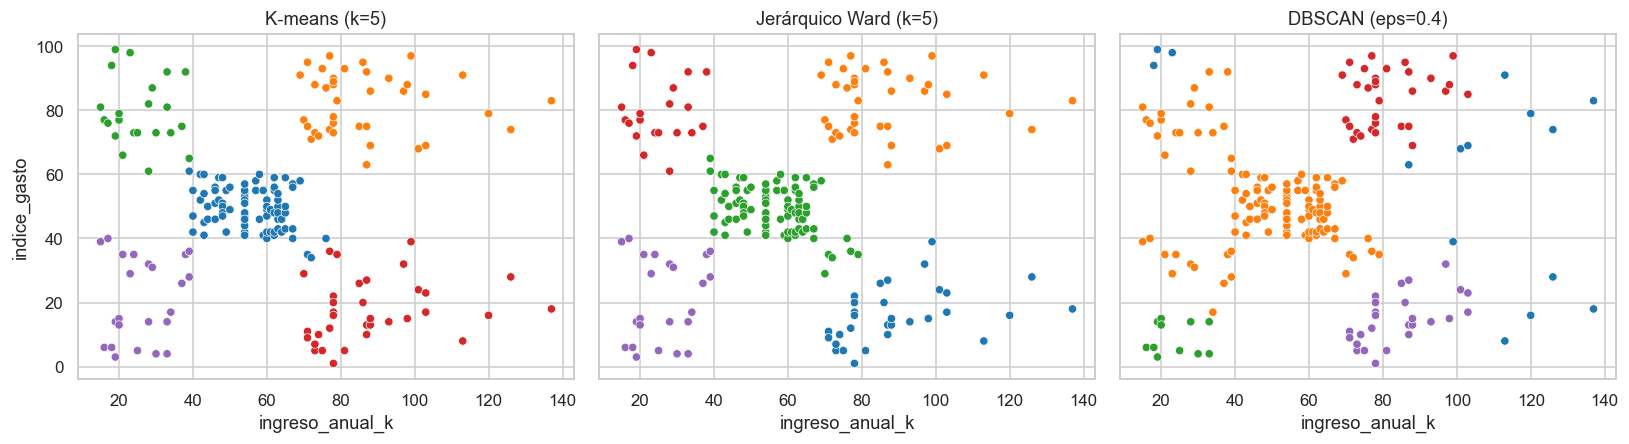

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for a, nombre in zip(ax, ["K-means (k=5)", "Jerárquico Ward (k=5)", "DBSCAN (eps=0.4)"]):
    sns.scatterplot(x=base["ingreso_anual_k"], y=base["indice_gasto"], hue=candidatos[nombre], palette="tab10", s=30, ax=a, legend=False)
    a.set_title(nombre)
plt.tight_layout(); plt.savefig(FIG / "04_comparacion_algoritmos.png", bbox_inches="tight"); plt.show()

**Decisión:** se mantiene **K-means con 5 segmentos**.
- Ward llega casi a los mismos grupos (ARI 0,94 con K-means) y a la misma silueta: los segmentos son una estructura real de los datos, no un artefacto del algoritmo.
- DBSCAN deja entre 4 % y 17,5 % de los clientes como ruido, sin segmento, y con eps = 0,5 junta todo en solo 2 grupos. Eso choca con RF.5 (todo cliente con consentimiento debe tener segmento), así que se descarta.
- Se probó además agregar la edad al modelo (celda siguiente): la silueta baja a 0,43 y la brecha por edad sigue en 43 pp. Meter la edad no corrige la equidad y haría que el modelo discrimine directamente por edad (riesgo R7), así que se descarta.

In [5]:
X3 = preparacion.escalar(base, ["edad", "ingreso_anual_k", "indice_gasto"])[0]
r_edad = evaluacion.evaluar(X3, modelado.kmeans(X3, 6).labels_, base, 6, con_estabilidad=False)
evaluacion.registrar_experimento("It.2", "K-means", "k=6", ["edad", "ingreso_anual_k", "indice_gasto"], r_edad,
                                 "descartado: segmenta por edad (R7)")
{k: round(v, 3) for k, v in r_edad.items()}

{'silueta': 0.427,
 'tamano_min_pct': 10.5,
 'estabilidad': nan,
 'ruido_pct': 0.0,
 'brecha_genero_pp': 13.576,
 'brecha_tramo_etario_pp': 43.333}

## 2. Fichas de perfil (RF.3) y composición por edad y género (RF.6)

In [6]:
base["segmento"] = modelado.ordenar_etiquetas(etiquetas_km, base["indice_gasto"].values)
tabla = fichas.construir_fichas(base)
tabla[["segmento", "nombre", "clientes", "pct_clientes", "edad_media", "ingreso_medio_k", "indice_gasto_medio", "pct_mujeres", "accion_sugerida"]]

,segmento,nombre,clientes,pct_clientes,edad_media,ingreso_medio_k,indice_gasto_medio,pct_mujeres,accion_sugerida
0,1,Premium,39,19.5,32.7,86.5,82.1,53.8,Ingreso y gasto altos. Fidelizar con beneficio...
1,2,Entusiastas,22,11.0,25.3,25.7,79.4,59.1,Gastan mucho en relación con su ingreso. Campa...
2,3,Estándar,81,40.5,42.7,55.3,49.5,59.3,Ingreso y gasto cercanos al promedio. Campañas...
3,4,Sensibles al precio,23,11.5,45.2,26.3,20.9,60.9,"Ingreso y gasto bajos. Ofertas de valor, patio..."
4,5,Potencial por activar,35,17.5,41.1,88.2,17.1,45.7,Ingreso alto pero gasta poco en el centro. Inv...


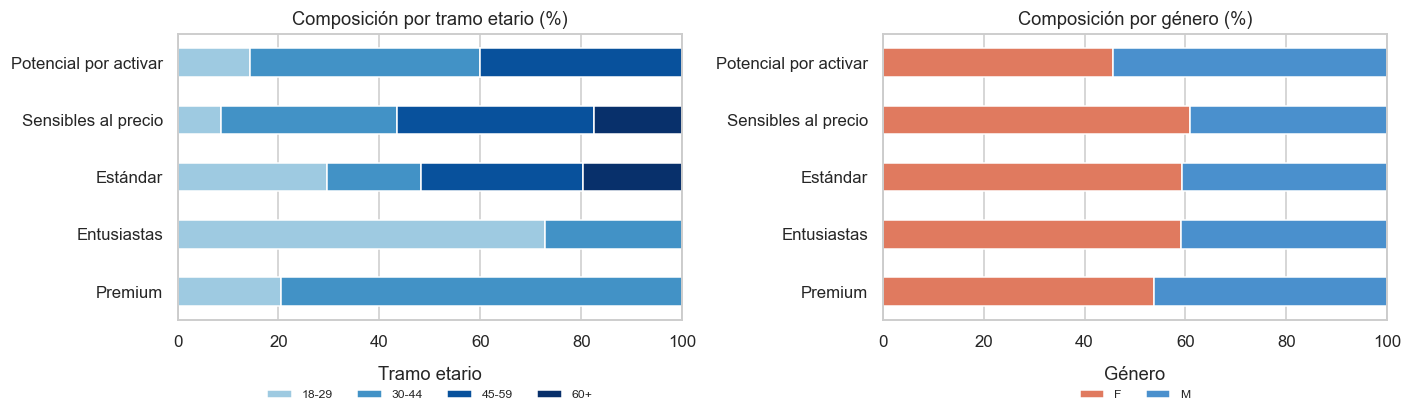

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
comp_t = evaluacion.composicion(base, "segmento", "tramo_etario")[config.ETIQUETAS_TRAMOS]
comp_t.index = tabla.set_index("segmento").loc[comp_t.index, "nombre"]
comp_t.plot.barh(stacked=True, ax=ax[0], color=["#9ecae1", "#4292c6", "#08519c", "#08306b"], edgecolor="white")
ax[0].set_title("Composición por tramo etario (%)")
comp_g = evaluacion.composicion(base, "segmento", "genero")
comp_g.index = comp_t.index
comp_g.plot.barh(stacked=True, ax=ax[1], color=["#e07a5f", "#4a90cd"], edgecolor="white"); ax[1].set_title("Composición por género (%)")
for a, titulo in zip(ax, ["Tramo etario", "Género"]):
    a.legend(title=titulo, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8, frameon=False)
    a.set_ylabel(""); a.set_xlim(0, 100)
plt.tight_layout(); plt.savefig(FIG / "04_composicion.png", bbox_inches="tight"); plt.show()

## 3. Evaluación de la iteración 2 (2.5.2)

In [8]:
r2 = evaluacion.evaluar(X, base["segmento"].values, base, k)
pd.DataFrame({"resultado": pd.Series(r2).round(3), }).T

,silueta,tamano_min_pct,estabilidad,ruido_pct,brecha_genero_pp,brecha_tramo_etario_pp
resultado,0.555,11.0,0.976,0.0,10.286,45.227


In [9]:
pd.Series(evaluacion.veredicto(r2), name="cumple").to_frame()

,cumple
"silueta >= 0,40",True
ningún segmento < 5 %,True
"estabilidad >= 0,80",True
brecha genero <= 15 pp,True
brecha tramo_etario <= 15 pp,False


**Resultado:** cumple silueta, tamaño, estabilidad y equidad por género (brecha de 10,3 pp). **No cumple la equidad por edad: brecha de 45,2 pp.** Los segmentos Premium y Entusiastas no tienen clientes de 45 años o más. La causa está en los datos, no en el modelo: el índice de gasto baja con la edad (r = −0,33, notebook 01).

**Desviación D-05 y acciones correctivas** (registradas en la planilla de control y en Trello):
1. La ficha de cada segmento con un tramo etario casi ausente lleva una alerta visible (columna `alerta_equidad`).
2. La lista de revisión de campañas (RF.9) agrega una regla: ninguna campaña por segmento puede quitar beneficios base a otros clientes.
3. En la iteración 3 se repite la revisión con la base con consentimiento y, si llegan las ventas reales (D-03), se contrasta si el índice de gasto subestima el gasto de los mayores.

**Decisión firmada (04/12, H3):** se avanza a la iteración 3 **con condiciones** (las tres acciones anteriores).

## 4. Herramienta v2: exportación para Marketing (RF.7)

In [10]:
ruta = fichas.exportar(base, tabla, "v2")
print(Path(ruta).relative_to(config.RAIZ))
pd.read_excel(ruta, sheet_name="Clientes por segmento").head()

reports/fichas_segmentos_v2.xlsx


,seudonimo,segmento,genero,tramo_etario,ingreso_anual_k,indice_gasto
0,9ffeeb2a812d,1,M,30-44,137,83
1,f6241b866428,1,M,30-44,87,63
2,c84c48f49fca,1,F,30-44,86,95
3,96985facf5c3,1,F,30-44,85,75
4,4c77897937f3,1,F,30-44,81,93
